# Lab 5.2: Tiền xử lý dữ liệu mua sắm

**Học phần:** Dữ liệu lớn (Big Data)  
**Mã số sinh viên:** 26410022

Bài này sử dụng `shopping_trends.csv` bạn cung cấp. DOCX đặt cạnh CSV trùng hệt đề Lab 5 về PDF; vì vậy Lab 5.2 tập trung vào kiểm tra và tiền xử lý dữ liệu bảng, không gán các bước tokenization cho những nhãn ngắn trong CSV.

## 1. Tải và kiểm tra dữ liệu

Khi chạy cục bộ, notebook đọc tệp trong repo. Trên Colab, notebook đọc cùng tệp qua GitHub Raw.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

local_paths = [Path("datasets/lab5/shopping_trends.csv"), Path("../datasets/lab5/shopping_trends.csv")]
local_path = next((p for p in local_paths if p.is_file()), None)
data_url = "https://raw.githubusercontent.com/shizziio/uit-DS200.G11.CN2.TTNT/main/datasets/lab5/shopping_trends.csv"
data = pd.read_csv(local_path if local_path else data_url)
print("Nguồn:", local_path if local_path else data_url)
print("Kích thước:", data.shape)
display(data.head())

Nguồn: datasets/lab5/shopping_trends.csv
Kích thước: (3900, 19)


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually


In [2]:
print("Kiểu dữ liệu:")
display(data.dtypes.to_frame("dtype"))
summary = pd.DataFrame({
    "Số ô thiếu": data.isna().sum(),
    "Tỷ lệ thiếu (%)": (data.isna().mean() * 100).round(2),
    "Số giá trị riêng": data.nunique(),
})
display(summary)
print("Dòng trùng hoàn toàn:", int(data.duplicated().sum()))
print("Customer ID trùng:", int(data["Customer ID"].duplicated().sum()))
print("Hai cột ưu đãi giống nhau ở mọi dòng:", data["Discount Applied"].equals(data["Promo Code Used"]))

Kiểu dữ liệu:


,dtype
Customer ID,int64
Age,int64
Gender,str
Item Purchased,str
Category,str
Purchase Amount (USD),int64
Location,str
Size,str
Color,str
Season,str


,Số ô thiếu,Tỷ lệ thiếu (%),Số giá trị riêng
Customer ID,0,0.0,3900
Age,0,0.0,53
Gender,0,0.0,2
Item Purchased,0,0.0,25
Category,0,0.0,4
Purchase Amount (USD),0,0.0,81
Location,0,0.0,50
Size,0,0.0,4
Color,0,0.0,25
Season,0,0.0,4


Dòng trùng hoàn toàn: 0
Customer ID trùng: 0
Hai cột ưu đãi giống nhau ở mọi dòng: True


## 2. Xem phân bố dữ liệu

Đếm giao dịch theo `Category` và vẽ phân bố `Purchase Amount (USD)`. Đây là bước khám phá dữ liệu trước khi mã hóa.

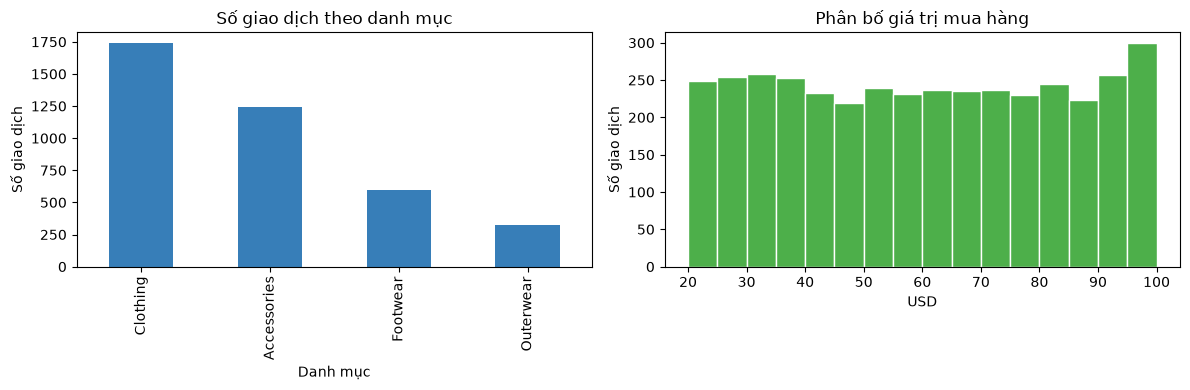

,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3900.000000
mean,44.068462,59.764359,3.749949,25.351538
std,15.207589,23.685392,0.716223,14.447125
min,18.000000,20.000000,2.500000,1.000000
25%,31.000000,39.000000,3.100000,13.000000
50%,44.000000,60.000000,3.700000,25.000000
75%,57.000000,81.000000,4.400000,38.000000
max,70.000000,100.000000,5.000000,50.000000


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
data["Category"].value_counts().plot.bar(ax=axes[0], color="#377eb8")
axes[0].set(title="Số giao dịch theo danh mục", xlabel="Danh mục", ylabel="Số giao dịch")
data["Purchase Amount (USD)"].plot.hist(ax=axes[1], bins=16, color="#4daf4a", edgecolor="white")
axes[1].set(title="Phân bố giá trị mua hàng", xlabel="USD", ylabel="Số giao dịch")
fig.tight_layout()
plt.show()
display(data[["Age", "Purchase Amount (USD)", "Review Rating", "Previous Purchases"]].describe())

## 3. Tiền xử lý

`Customer ID` là mã định danh nên bỏ khỏi ma trận đặc trưng. Hai cột `Discount Applied` và `Promo Code Used` trùng giá trị ở cả 3.900 dòng, nên giữ một cột. Các cột số dùng median imputation và `StandardScaler`; các cột phân loại dùng mode imputation và one-hot encoding. Tệp hiện không có ô thiếu, nhưng pipeline vẫn xử lý được nếu dữ liệu tương lai có ô thiếu. Vì đề chưa chỉ định biến mục tiêu hoặc mô hình, bước này tạo ma trận đặc trưng cho phân tích tiếp theo.

In [4]:
assert data["Customer ID"].is_unique
redundant = data["Discount Applied"].equals(data["Promo Code Used"])
drop_columns = ["Customer ID"] + (["Promo Code Used"] if redundant else [])
features = data.drop(columns=drop_columns)
numeric_columns = features.select_dtypes(include="number").columns.tolist()
categorical_columns = features.select_dtypes(exclude="number").columns.tolist()
transformer = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), numeric_columns),
        ("cat", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical_columns),
    ],
    verbose_feature_names_out=False,
)
processed = pd.DataFrame(
    transformer.fit_transform(features),
    columns=transformer.get_feature_names_out(),
    index=data.index,
)
print("Cột số:", numeric_columns)
print("Số cột phân loại:", len(categorical_columns))
print("Kích thước sau xử lý:", processed.shape)
print("Ô thiếu còn lại:", int(processed.isna().sum().sum()))
display(processed.iloc[:5, :12])

Cột số: ['Age', 'Purchase Amount (USD)', 'Review Rating', 'Previous Purchases']
Số cột phân loại: 13
Kích thước sau xử lý: (3900, 147)
Ô thiếu còn lại: 0


,Age,Purchase Amount (USD),Review Rating,Previous Purchases,Gender_Female,Gender_Male,Item Purchased_Backpack,Item Purchased_Belt,Item Purchased_Blouse,Item Purchased_Boots,Item Purchased_Coat,Item Purchased_Dress
0,0.718913,-0.285629,-0.907584,-0.785831,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1,-1.648629,0.178852,-0.907584,-1.616552,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.390088,0.558882,-0.907584,-0.162789,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,-1.517099,1.276716,-0.349027,1.637107,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.061263,-0.454531,-1.466141,0.391025,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


## 4. Kiểm tra kết quả

Sau mã hóa, mọi cột là số. Các cột gốc được chuẩn hóa có trung bình gần 0 và độ lệch chuẩn gần 1. Khi dùng cho mô hình dự đoán sau này, cần chia train/test trước rồi `fit` pipeline trên tập train để tránh rò rỉ dữ liệu.

In [5]:
assert processed.shape[0] == len(data)
assert not processed.isna().any().any()
print("Tất cả cột sau xử lý đều là số:", all(pd.api.types.is_numeric_dtype(t) for t in processed.dtypes))
display(processed[numeric_columns].agg(["mean", "std"]).round(4))

Tất cả cột sau xử lý đều là số: True


,Age,Purchase Amount (USD),Review Rating,Previous Purchases
mean,-0.0000,-0.0000,0.0000,0.0000
std,1.0001,1.0001,1.0001,1.0001


**Kết quả:** Bộ dữ liệu có 3.900 dòng, 19 cột, không có ô thiếu hoặc dòng trùng. Sau khi bỏ mã định danh/cột trùng và mã hóa, ma trận có 147 cột số. `lab5_2.py` có thể lưu ma trận và biểu đồ vào `lab5_2/outputs/`.